# Weather EDA — Extra Analyses (course-aligned)

Supplements `eda.ipynb` with the diagnostics emphasized in the Time-Series lectures:

1. **Stationarity** — rolling mean/variance plots + ADF **and** KPSS (use tests together).
2. **ACF & PACF** — per target, for AR-order identification (PACF cuts off → AR(p)).
3. **Decomposition** — trend / seasonal / residual for every target (daily + annual cycles).
4. **Lagged cross-correlation** — the signal that justifies a **multivariate VAR** over 7 separate models.

Targets: `temp, rh, dew, pressure, cloud, wx, wy` (matches the VAR pipeline).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller, kpss, ccf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

sns.set_theme(style="whitegrid")


def clean_names(df):
    pref = {
        "temperature_2m": "temp", "relative_humidity_2m": "rh",
        "dew_point_2m": "dew", "surface_pressure": "pressure",
        "cloud_cover": "cloud", "wind_speed_10m": "wind_speed",
        "wind_direction_10m": "wind_dir",
    }
    mapping = {c: pref.get(c.split(" (")[0].strip(), c) for c in df.columns}
    return df.rename(columns=mapping)


# Load + clean (data is already hourly)
df = pd.read_csv("data/weather_dataset.csv")
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time").sort_index().asfreq("h")
df = clean_names(df)

# Wind decomposition (circular -> Cartesian)
rad = np.radians(df["wind_dir"])
df["wx"] = df["wind_speed"] * np.cos(rad)
df["wy"] = df["wind_speed"] * np.sin(rad)

TARGETS = ["temp", "rh", "dew", "pressure", "cloud", "wx", "wy"]
data = df[TARGETS].dropna()
daily = data.resample("D").mean()
print("hourly shape:", data.shape, " | daily shape:", daily.shape)
data.head()

hourly shape: (43824, 7)  | daily shape: (1826, 7)


,temp,rh,dew,pressure,cloud,wx,wy
time,,,,,,,
2021-01-01 00:00:00,9.4,49,-0.8,1025.7,0,6.881012,4.641301
2021-01-01 01:00:00,9.1,50,-0.7,1025.4,0,7.505055,3.990508
2021-01-01 02:00:00,8.8,51,-0.8,1025.0,0,8.284544,3.516580
2021-01-01 03:00:00,8.6,50,-1.3,1024.7,11,9.735430,3.933369
2021-01-01 04:00:00,8.5,50,-1.5,1025.0,46,10.477178,4.233055


## 1. Stationarity

### 1a. Rolling mean & variance (visual check)
A stationary series has a roughly flat rolling mean and rolling variance. Weather has an
annual cycle, so expect a wavy mean — that's *seasonality*, not a unit root.

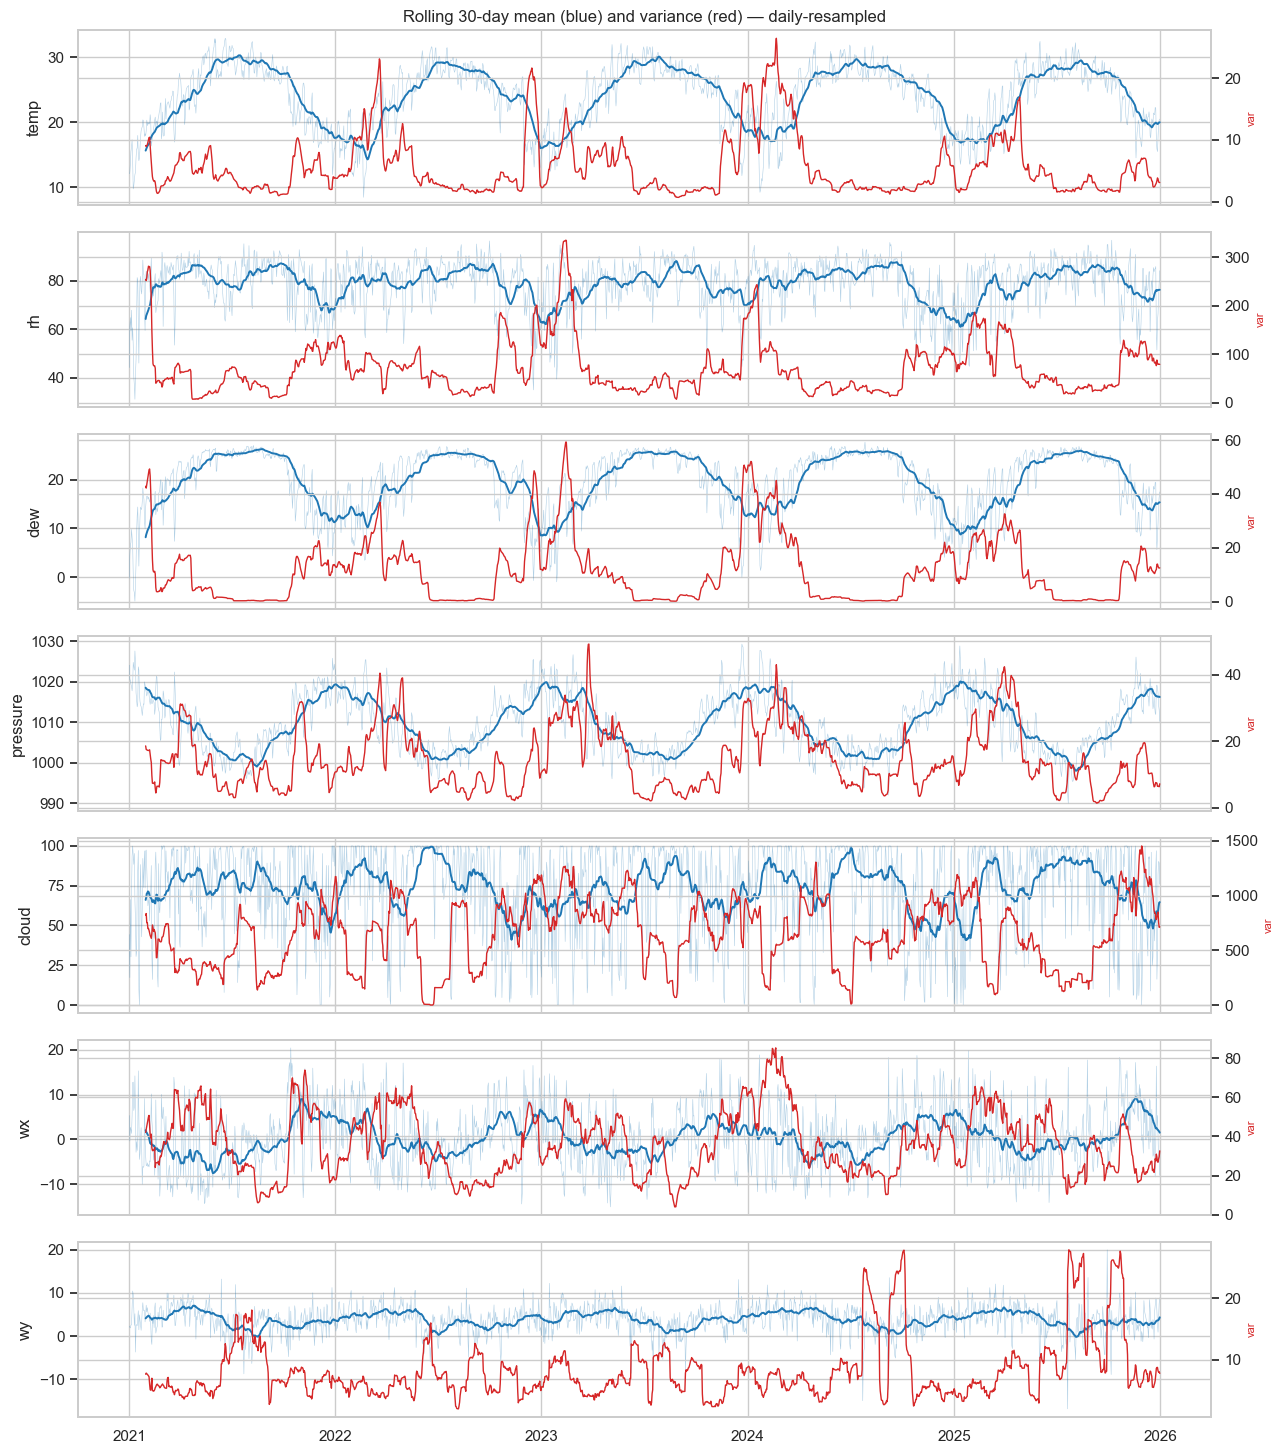

In [2]:
fig, axes = plt.subplots(len(TARGETS), 1, figsize=(13, 2.1 * len(TARGETS)), sharex=True)
for ax, col in zip(axes, TARGETS):
    s = daily[col]
    ax.plot(s.index, s, lw=0.4, alpha=0.35, color="tab:blue")
    ax.plot(s.index, s.rolling(30).mean(), lw=1.4, color="tab:blue", label="30d mean")
    ax2 = ax.twinx()
    ax2.plot(s.index, s.rolling(30).var(), lw=1.0, color="tab:red", label="30d var")
    ax2.set_ylabel("var", color="tab:red", fontsize=8)
    ax.set_ylabel(col)
axes[0].set_title("Rolling 30-day mean (blue) and variance (red) — daily-resampled")
fig.tight_layout()
plt.show()

### 1b. ADF + KPSS (use both — opposite null hypotheses)
- **ADF** null = *has a unit root* → small p ⇒ stationary.
- **KPSS** null = *stationary* → large p ⇒ stationary.

Agreement on "stationary" is strong evidence; disagreement usually flags deterministic
seasonality/trend rather than a stochastic trend.

In [3]:
rows = []
for col in TARGETS:
    s = data[col].dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    adf_stat = "stationary" if adf_p <= 0.05 else "NON-stat"
    kpss_stat = "stationary" if kpss_p >= 0.05 else "NON-stat"
    if adf_stat == "stationary" and kpss_stat == "stationary":
        verdict = "STATIONARY"
    elif adf_stat == "NON-stat" and kpss_stat == "NON-stat":
        verdict = "non-stationary"
    else:
        verdict = "trend/borderline"
    rows.append([col, round(adf_p, 4), round(kpss_p, 4), adf_stat, kpss_stat, verdict])

pd.DataFrame(rows, columns=["var", "ADF p", "KPSS p", "ADF", "KPSS", "verdict"])

C:\Users\vuthe\AppData\Local\Temp\ipykernel_5764\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


C:\Users\vuthe\AppData\Local\Temp\ipykernel_5764\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


C:\Users\vuthe\AppData\Local\Temp\ipykernel_5764\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


C:\Users\vuthe\AppData\Local\Temp\ipykernel_5764\2180858787.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_p = kpss(s, regression="c", nlags="auto")[1]


,var,ADF p,KPSS p,ADF,KPSS,verdict
0,temp,0.0,0.0486,stationary,NON-stat,trend/borderline
1,rh,0.0,0.1000,stationary,stationary,STATIONARY
2,dew,0.0,0.0994,stationary,stationary,STATIONARY
3,pressure,0.0,0.1000,stationary,stationary,STATIONARY
4,cloud,0.0,0.1000,stationary,stationary,STATIONARY
5,wx,0.0,0.0298,stationary,NON-stat,trend/borderline
6,wy,0.0,0.1000,stationary,stationary,STATIONARY


## 2. ACF & PACF (model-order identification)

Read per the lectures:
- **ACF tails off, PACF cuts off after lag p** ⇒ AR(p) structure.
- A bump near **lag 24** reflects the daily cycle.

This cross-checks the AIC lag order used by the VAR pipeline.

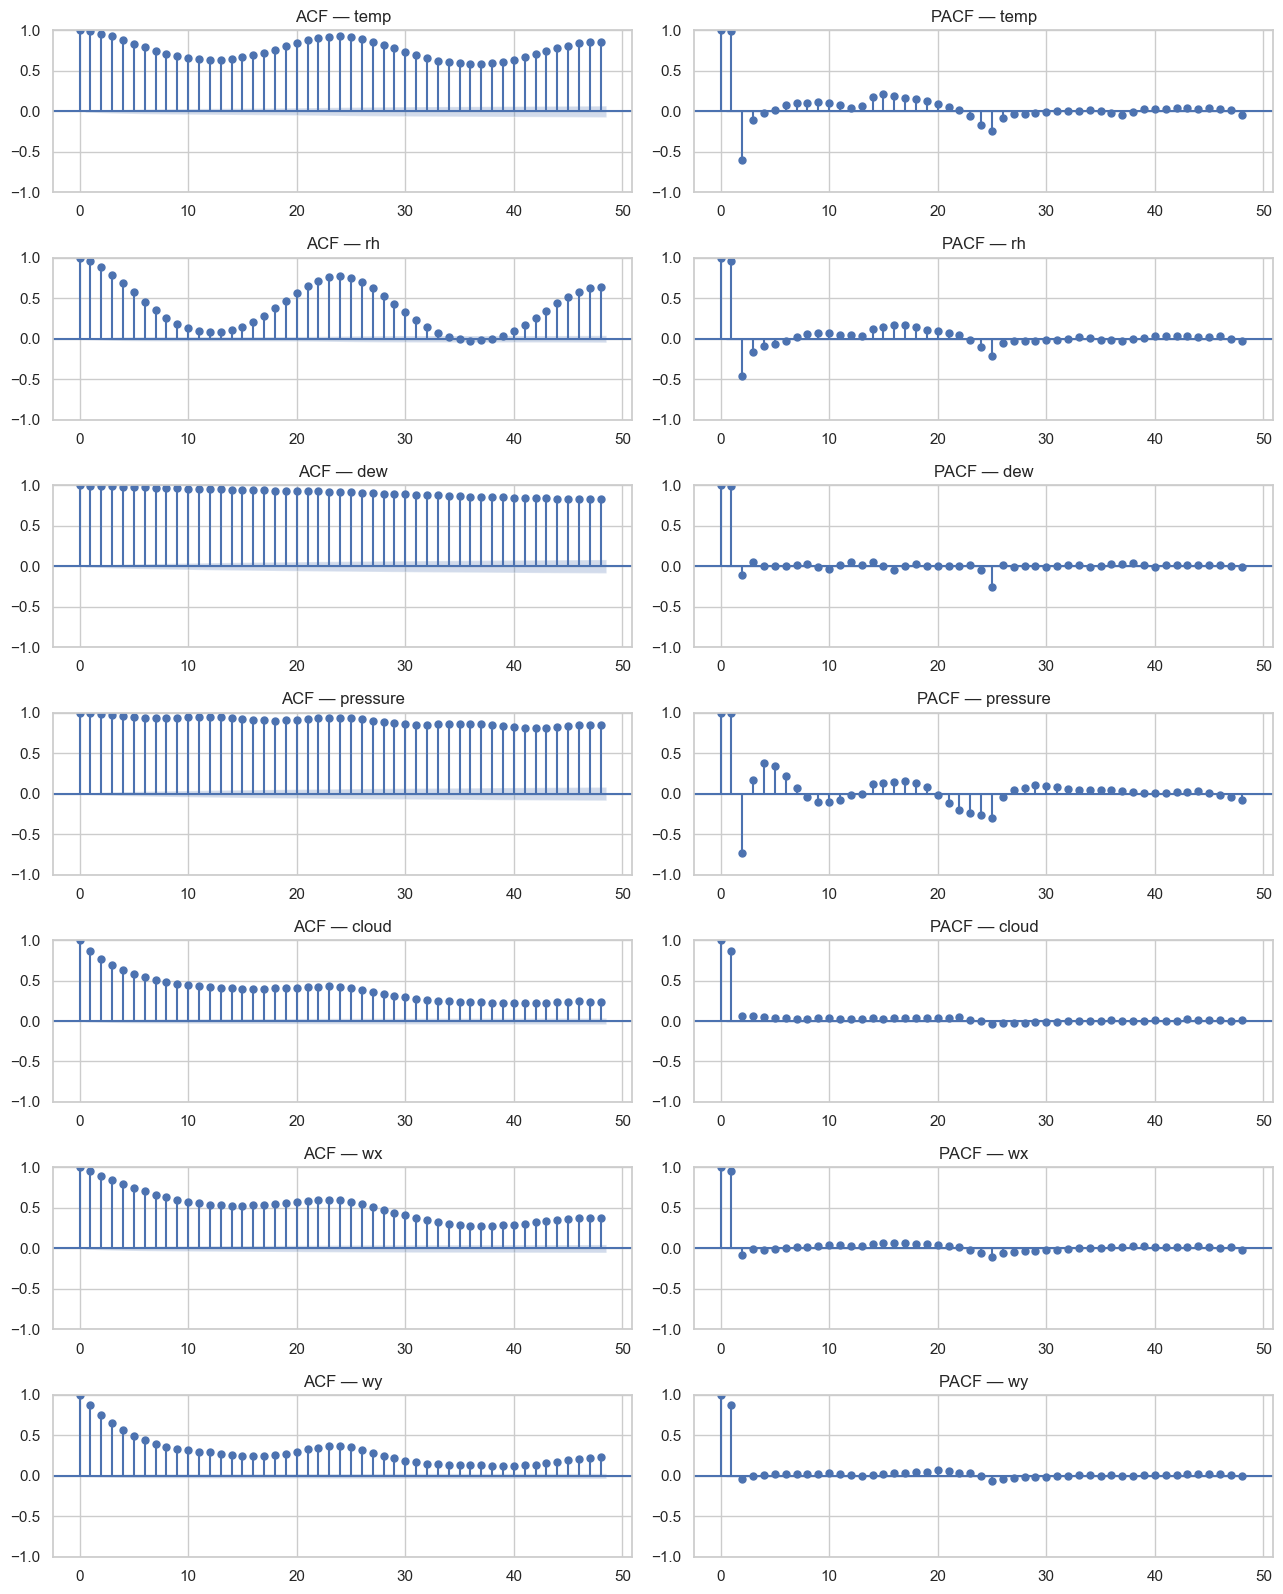

In [4]:
fig, axes = plt.subplots(len(TARGETS), 2, figsize=(13, 2.3 * len(TARGETS)))
for i, col in enumerate(TARGETS):
    plot_acf(data[col], lags=48, ax=axes[i, 0], title=f"ACF — {col}")
    plot_pacf(data[col], lags=48, ax=axes[i, 1], method="ywm", title=f"PACF — {col}")
fig.tight_layout()
plt.show()

## 3. Decomposition (Trend + Seasonal + Residual)

### 3a. Daily cycle (standardized mean by hour-of-day)
Shows which variables have a strong 24-h cycle. (Peaks shifted ~+7h vs local time → timestamps look like **UTC**.)

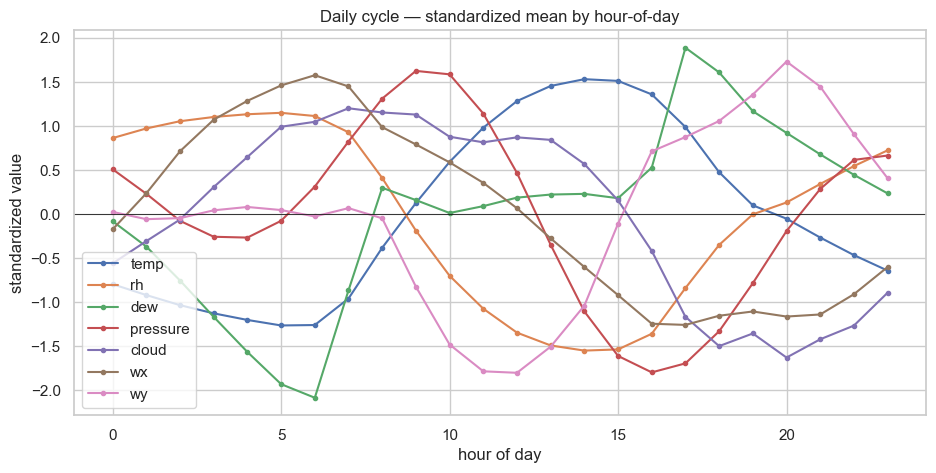

In [5]:
prof = data.groupby(data.index.hour).mean()
profz = (prof - prof.mean()) / prof.std()
ax = profz.plot(figsize=(11, 5), marker=".")
ax.set_title("Daily cycle — standardized mean by hour-of-day")
ax.set_xlabel("hour of day")
ax.set_ylabel("standardized value")
ax.axhline(0, color="k", lw=0.6)
plt.show()

### 3b. Annual decomposition per target (period = 365 days)
Additive model on the daily-resampled series. The **seasonal** panel exposes the annual
cycle; the **trend** panel shows any slow multi-year drift.

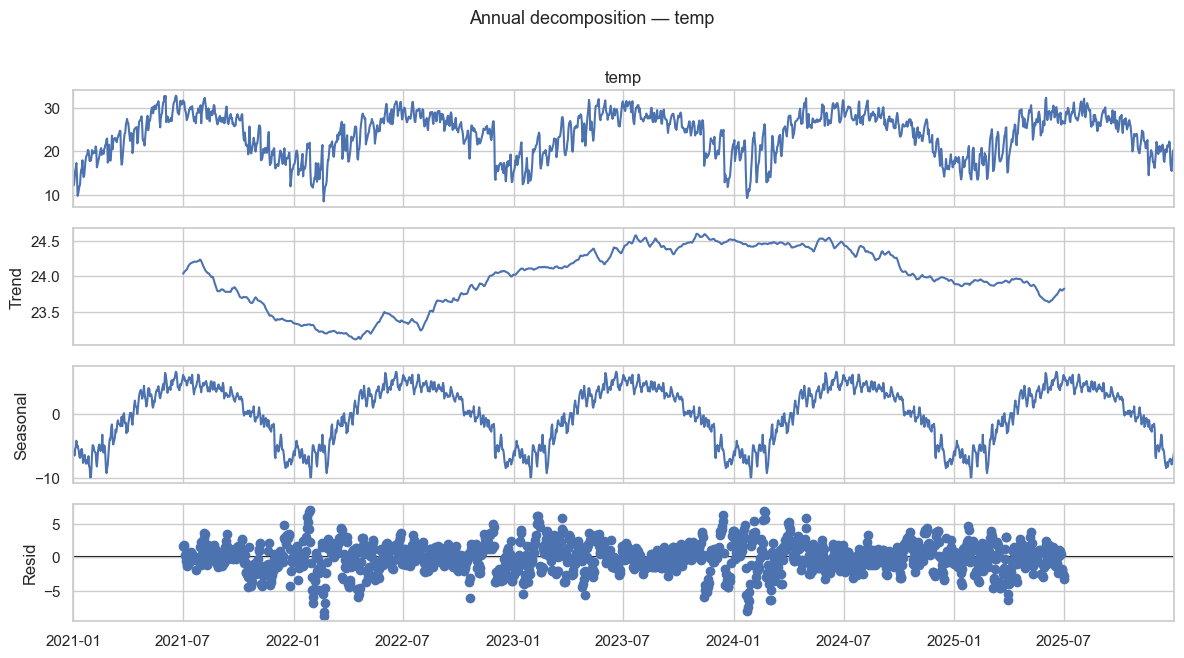

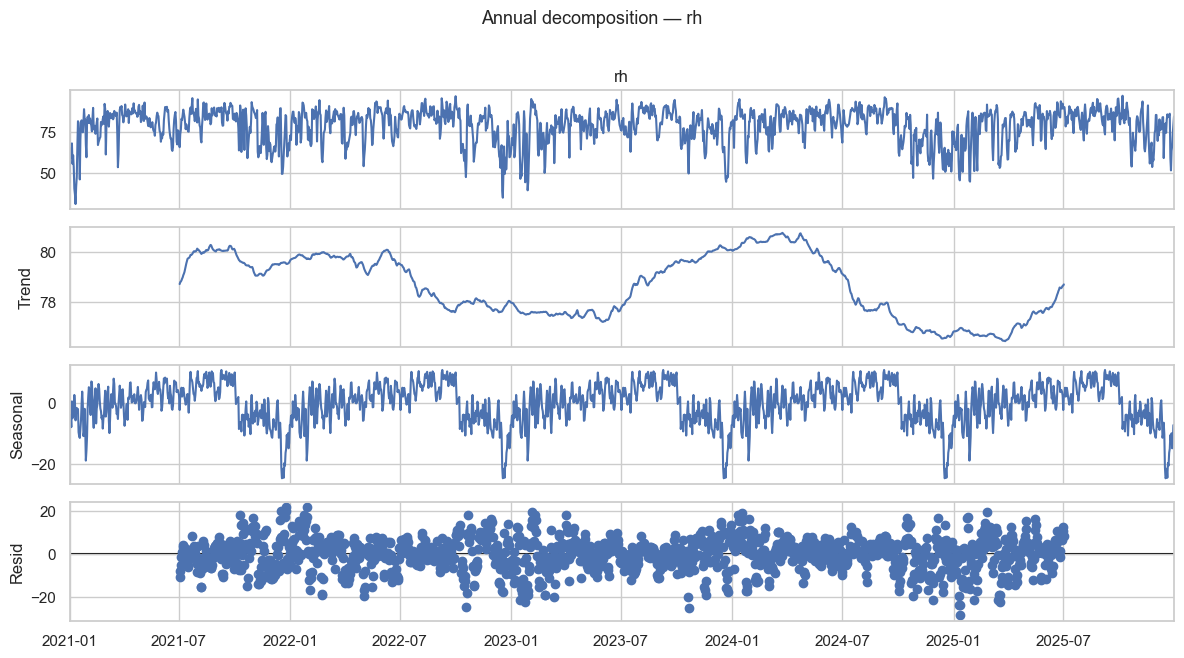

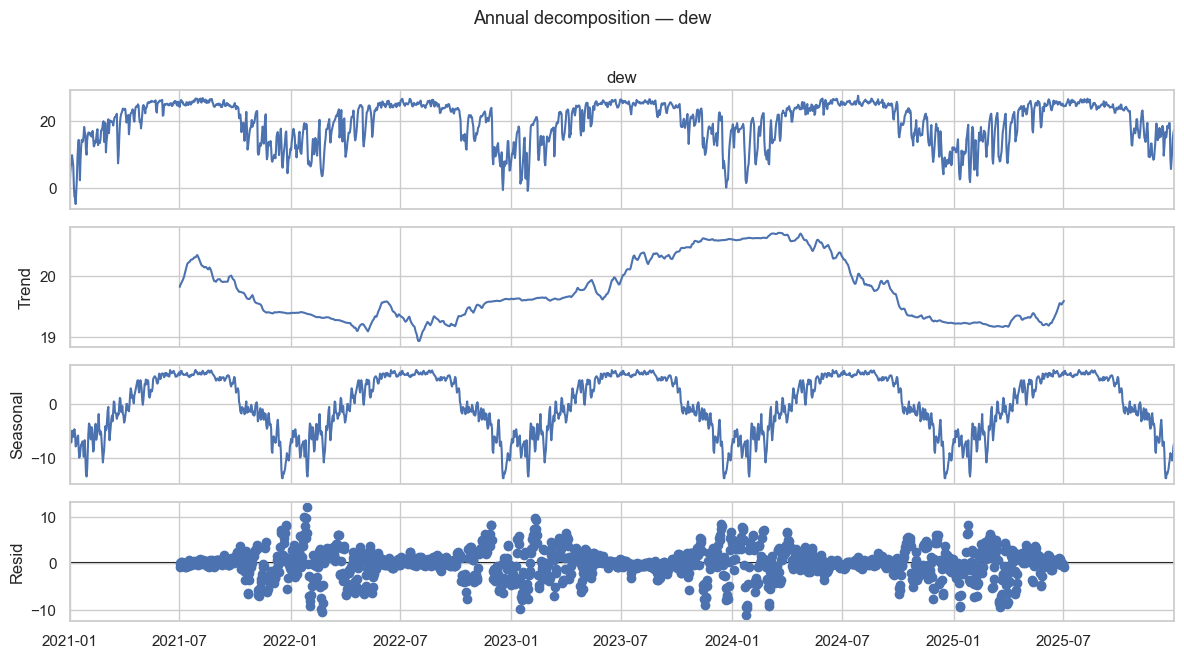

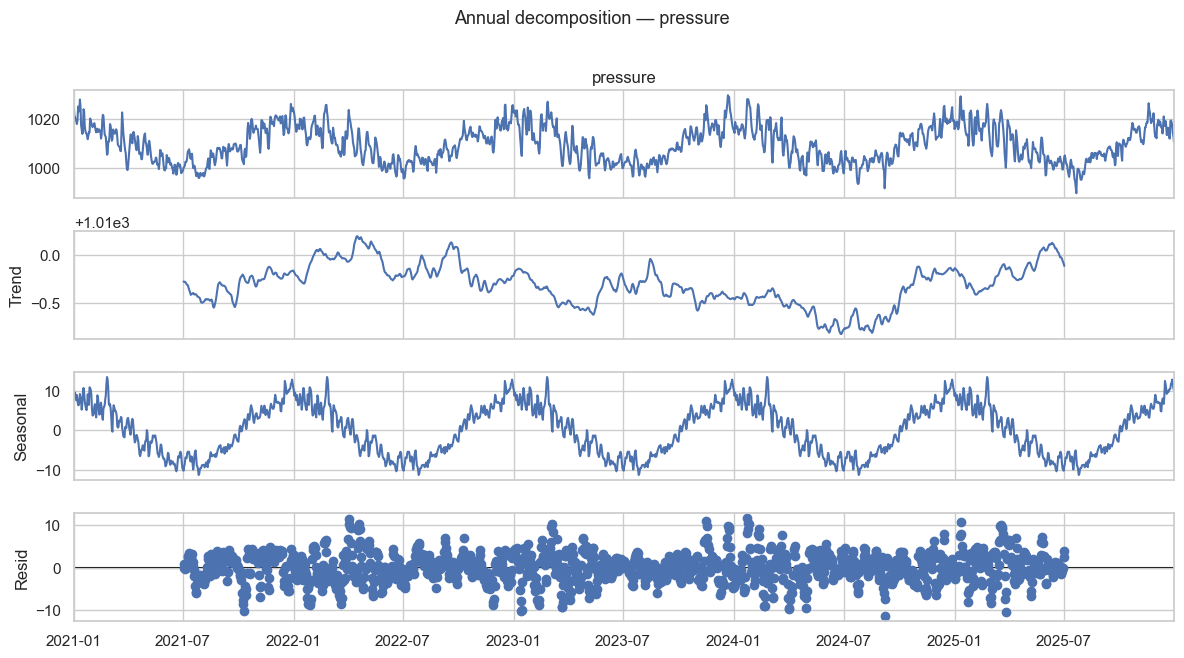

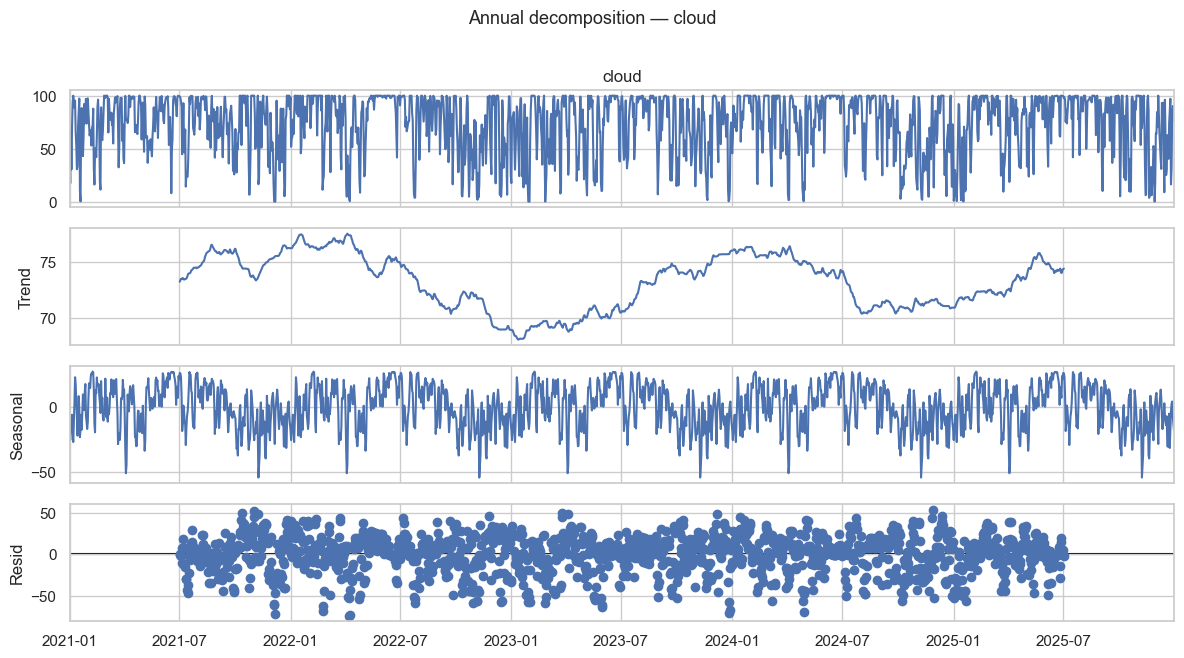

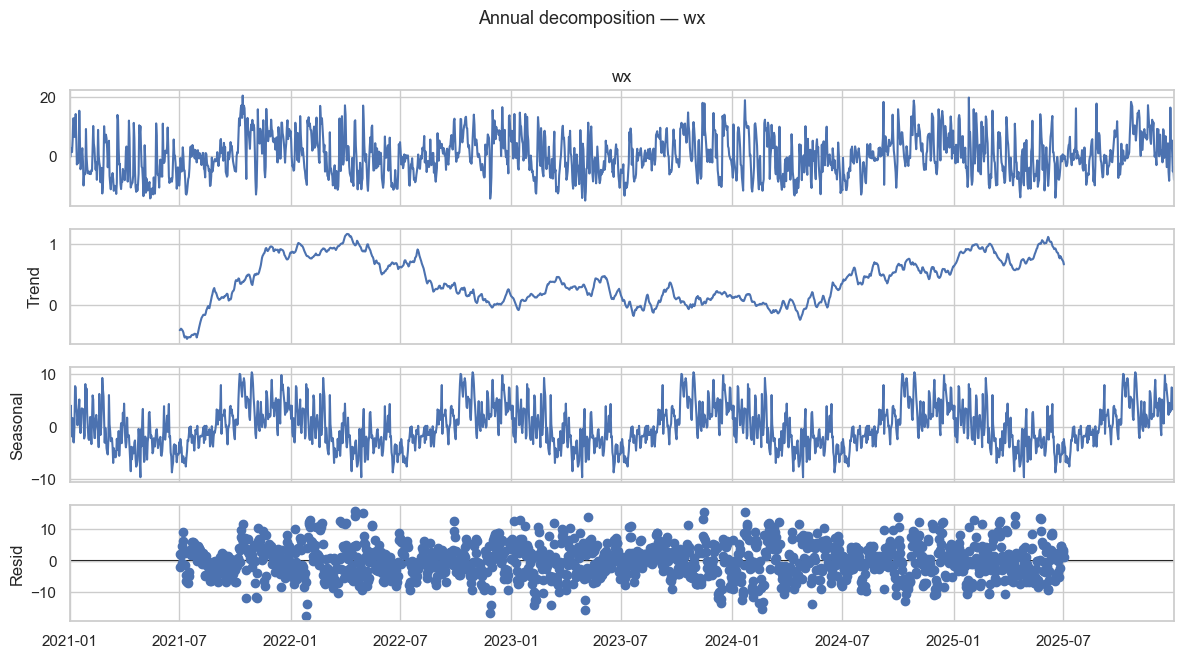

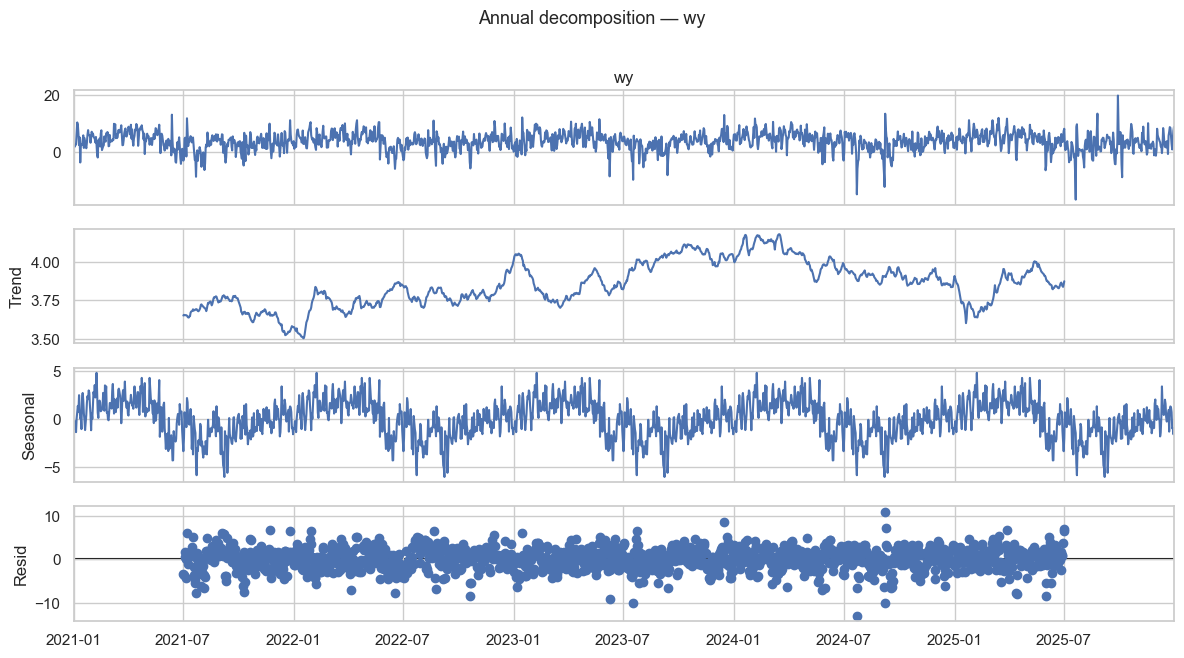

In [6]:
for col in TARGETS:
    res = seasonal_decompose(daily[col].dropna(), model="additive", period=365)
    fig = res.plot()
    fig.set_size_inches(12, 6.5)
    fig.suptitle(f"Annual decomposition — {col}", y=1.01, fontsize=13)
    fig.tight_layout()
    plt.show()

## 4. Lagged cross-correlation (why VAR, not 7 separate models)

If one variable's **past** correlates with another's **present**, a multivariate model (VAR)
can exploit it — something 7 independent AR/ARIMA models cannot.

### 4a. `temp` leading the other variables

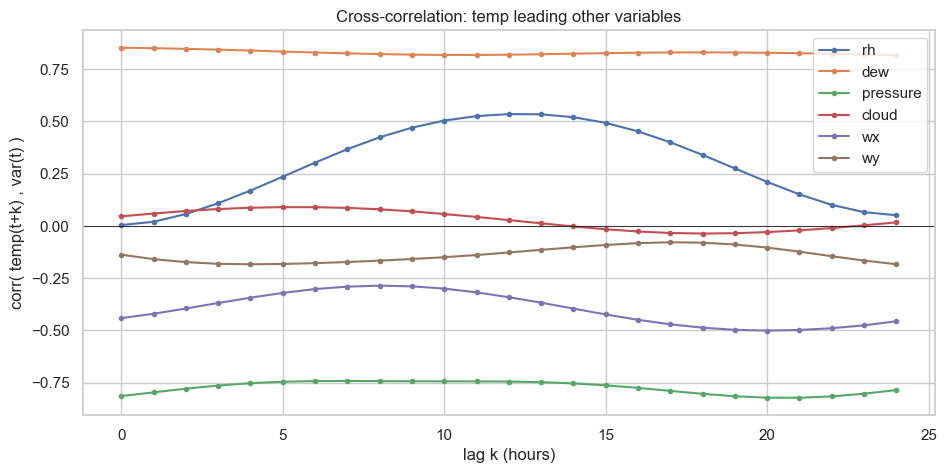

In [7]:
maxlag = 24
ref = "temp"
fig, ax = plt.subplots(figsize=(11, 5))
for col in TARGETS:
    if col == ref:
        continue
    c = ccf(data[ref], data[col])[: maxlag + 1]
    ax.plot(range(maxlag + 1), c, marker=".", label=col)
ax.axhline(0, color="k", lw=0.6)
ax.set_xlabel("lag k (hours)")
ax.set_ylabel(f"corr( {ref}(t+k) , var(t) )")
ax.set_title(f"Cross-correlation: {ref} leading other variables")
ax.legend()
plt.show()

### 4b. Lagged cross-correlation matrix
`corr( row(t), col(t-lag) )` — does each column's recent past help predict each row?
Strong off-diagonal values are the multivariate signal VAR uses.

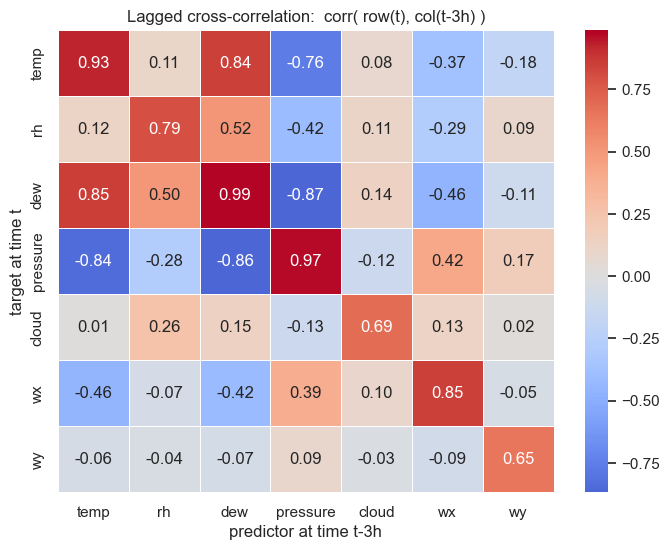

In [8]:
lag = 3  # hours
M = pd.DataFrame(index=TARGETS, columns=TARGETS, dtype=float)
for a in TARGETS:
    for b in TARGETS:
        M.loc[a, b] = np.corrcoef(data[a].values[lag:], data[b].values[:-lag])[0, 1]

plt.figure(figsize=(8, 6))
sns.heatmap(M.astype(float), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title(f"Lagged cross-correlation:  corr( row(t), col(t-{lag}h) )")
plt.ylabel("target at time t")
plt.xlabel(f"predictor at time t-{lag}h")
plt.show()

## Takeaways

- **Stationarity:** ADF + rolling stats indicate no unit root; KPSS borderline cases (e.g. `temp`, `wx`)
  reflect the **annual** cycle, not a stochastic trend → no differencing needed (`d=0`).
- **ACF/PACF:** PACF cutoff after a few lags supports a low base AR order; the lag-24 bump is the daily cycle
  the `VAR(p)` captures through its lags.
- **Decomposition:** strong **daily + annual** seasonality; trends are mild/non-monotonic. The annual cycle
  (period ≫ lag order) is the part VAR can't model directly — motivates seasonal `exog` terms.
- **Cross-correlation:** clear lagged links between variables justify the **multivariate VAR** over
  independent univariate models.